In [168]:
import pandas as pd
import matplotlib.pyplot as plt

In [78]:
# Pandas params

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

In [148]:
PATH_PROJECAO_2024 = './data/projecao_2024.xlsx'
PATH_FINANCAS_INSS_2020 = './data/finanças_inss_2020.xlsx'
PATH_FINANCAS_INSS_2021 = './data/finanças_inss_2021.xlsx'
PATH_FINANCAS_INSS_2022 = './data/finanças_inss_2022.xlsx'
PATH_FINANCAS_INSS_2023 = './data/finanças_inss_2023.xlsx'
PATH_FINANCAS_INSS_2024 = './data/finanças_inss_2024.xlsx'
PATH_FINANCAS_INSS_2025 = './data/finanças_inss_2025.xlsx'

In [ ]:
def import_data_proj(PATH):

    df = pd.read_excel(PATH)

    # Excluindo header e arrumando cabeçalho
    df = df.iloc[5:].reset_index(drop=True)
    df.columns = df.iloc[0]
    df = df.iloc[1:].reset_index(drop=True)

    cols = df.columns[4:69]
    df[cols] = df[cols].apply(pd.to_numeric, errors='coerce')

    return df

def import_data_fin(PATH):

    sheets = pd.read_excel(PATH, sheet_name=None)

    dfs = []

    for i, (nome, df) in enumerate(sheets.items()):
        
        # Transpondo df
        if nome == '22C40_01' or nome == '22C40_01 2' or nome == '22C40_02' or nome == '22C40_02 2':
            if i == 0:
                df = df.T.iloc[:, [3, 4, 20, 29, 40]].reset_index(drop=True)
            else:
                df = df.T.iloc[:, [4, 5, 21, 30, 41]].reset_index(drop=True)
        else:
            if i == 0:
                df = df.T.iloc[:, [3, 4, 20, 29, 44]].reset_index(drop=True)
            else:
                df = df.T.iloc[:, [4, 5, 21, 30, 45]].reset_index(drop=True)

        # Ajustando cabeçalho
        df = df.iloc[1:].reset_index(drop=True)
        df.columns = ['Mes', 'Arrecadacao_Bruta', 'Arrecadacao_Liquida', 'Total_Beneficios', 'Resultado_Primario']
        df = df.rename(columns={float('nan'): 'Mes'})

        # Convertendo pra numerico
        cols = df.columns[1:5]
        df[cols] = df[cols].apply(pd.to_numeric, errors='coerce')

        dfs.append(df)

    # Concatenando as abas
    df_final = pd.concat(dfs, ignore_index=True)

    return df_final


In [99]:
#importando
PROJECAO_2024 = import_data_proj(PATH_PROJECAO_2024)
PROJECAO_2024.head()

0,ANO,CÓD.,SIGLA,LOCAL,POP_T,POP_H,POP_M,0-1_T,0-1_H,0-1_M,0-4_T,0-4_H,0-4_M,0-14_T,0-14_H,0-14_M,15-17_T,15-17_H,15-17_M,18-21_T,18-21_H,18-21_M,15-59_T,15-59_H,15-59_M,15-64_T,15-64_H,15-64_M,60+_T,60+_H,60+_M,65+_T,65+_H,65+_M,80+_T,80+_H,80+_M,P_H,P_M,P_0-1_T,P_0-1_H,P_0-1_M,P_0-4_T,P_0-4_H,P_0-4_M,P_0-14_T,P_0-14_H,P_0-14_M,P_15-17_T,P_15-17_H,P_15-17_M,P_18-21_T,P_18-21_H,P_18-21_M,P_15-59_T,P_15-59_H,P_15-59_M,P_15-64_T,P_15-64_H,P_15-64_M,P_60+_T,P_60+_H,P_60+_M,P_65+_T,P_65+_H,P_65+_M,P_80+_T,P_80+_H,P_80+_M
0,2000,0,BR,Brasil,174695935,85720706,88975229,3423475,1739603,1683872,17281547,8739233,8542314,52259915,26250061,26009854,10756025,5364807,5391218,13941492,6917914,7023578,107206099,52595172,54610927,111908697,54827057,57081640,15229921,6875473,8354448,10527323,4643588,5883735,2032255,815147,1217108,0.490685,0.509315,0.019597,0.009958,0.009639,0.098924,0.050025,0.048898,0.299148,0.150261,0.148886,0.061570,0.030709,0.030861,0.079804,0.039600,0.040205,0.613673,0.301067,0.312606,0.640591,0.313843,0.326749,0.087180,0.039357,0.047823,0.060261,0.026581,0.033680,0.011633,0.004666,0.006967
1,2001,0,BR,Brasil,177003743,86821427,90182316,3347313,1704785,1642528,17123682,8678327,8445355,51985452,26141862,25843590,10754345,5366865,5387480,14098490,6999422,7099068,109370030,53626935,55743095,114176772,55907994,58268778,15648261,7052630,8595631,10841519,4771571,6069948,2097640,840643,1256997,0.490506,0.509494,0.018911,0.009631,0.009280,0.096742,0.049029,0.047713,0.293697,0.147691,0.146006,0.060758,0.030321,0.030437,0.079651,0.039544,0.040107,0.617897,0.302971,0.314926,0.645053,0.315858,0.329195,0.088406,0.039845,0.048562,0.061250,0.026957,0.034293,0.011851,0.004749,0.007102
2,2002,0,BR,Brasil,179228254,87882321,91345933,3274356,1671125,1603231,16906493,8586481,8320012,51668727,26015353,25653374,10710421,5346777,5363644,14194815,7052200,7142615,111483677,54633224,56850453,116386875,56959543,59427332,16075850,7233744,8842106,11172652,4907425,6265227,2173094,868422,1304672,0.490337,0.509663,0.018269,0.009324,0.008945,0.094329,0.047908,0.046421,0.288284,0.145152,0.143132,0.059759,0.029832,0.029926,0.079200,0.039348,0.039852,0.622021,0.304825,0.317196,0.649378,0.317804,0.331573,0.089695,0.040361,0.049334,0.062338,0.027381,0.034957,0.012125,0.004845,0.007279
3,2003,0,BR,Brasil,181377654,88907299,92470355,3212295,1642237,1570058,16640256,8468239,8172017,51329911,25879671,25450240,10629257,5307637,5321620,14246042,7082812,7163230,113528885,55605887,57922998,118532883,57979191,60553692,16518858,7421741,9097117,11514860,5048437,6466423,2256815,898154,1358661,0.490178,0.509822,0.017711,0.009054,0.008656,0.091744,0.046688,0.045055,0.283000,0.142684,0.140316,0.058603,0.029263,0.029340,0.078544,0.039050,0.039493,0.625925,0.306575,0.319350,0.653514,0.319660,0.333854,0.091074,0.040919,0.050156,0.063486,0.027834,0.035652,0.012443,0.004952,0.007491
4,2004,0,BR,Brasil,183469593,89905311,93564282,3163041,1619035,1544006,16343284,8332757,8010527,50980818,25739832,25240986,10528236,5258751,5269485,14260614,7094509,7166105,115497445,56542251,58955194,120624088,58972565,61651523,16991330,7623228,9368102,11864687,5192914,6671773,2348541,930109,1418432,0.490028,0.509972,0.017240,0.008825,0.008416,0.089079,0.045418,0.043661,0.277871,0.140295,0.137576,0.057384,0.028663,0.028721,0.077727,0.038669,0.039059,0.629518,0.308183,0.321335,0.657461,0.321430,0.336031,0.092611,0.041550,0.051061,0.064668,0.028304,0.036364,0.012801,0.005070,0.007731


In [100]:
PROJECAO_2024.info() 

<class 'pandas.DataFrame'>
RangeIndex: 2343 entries, 0 to 2342
Data columns (total 69 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ANO        2343 non-null   object 
 1   CÓD.       2343 non-null   object 
 2   SIGLA      2343 non-null   str    
 3   LOCAL      2343 non-null   str    
 4   POP_T      2343 non-null   int64  
 5   POP_H      2343 non-null   int64  
 6   POP_M      2343 non-null   int64  
 7   0-1_T      2343 non-null   int64  
 8   0-1_H      2343 non-null   int64  
 9   0-1_M      2343 non-null   int64  
 10  0-4_T      2343 non-null   int64  
 11  0-4_H      2343 non-null   int64  
 12  0-4_M      2343 non-null   int64  
 13  0-14_T     2343 non-null   int64  
 14  0-14_H     2343 non-null   int64  
 15  0-14_M     2343 non-null   int64  
 16  15-17_T    2343 non-null   int64  
 17  15-17_H    2343 non-null   int64  
 18  15-17_M    2343 non-null   int64  
 19  18-21_T    2343 non-null   int64  
 20  18-21_H    2343 non

**FIM PROJEÇÕES**


In [ ]:
FINANCAS_INSS_2020 = import_data_fin(PATH_FINANCAS_INSS_2020)
FINANCAS_INSS_2021 = import_data_fin(PATH_FINANCAS_INSS_2021)
FINANCAS_INSS_2022 = import_data_fin(PATH_FINANCAS_INSS_2022)
FINANCAS_INSS_2023 = import_data_fin(PATH_FINANCAS_INSS_2023)
FINANCAS_INSS_2024 = import_data_fin(PATH_FINANCAS_INSS_2024)
FINANCAS_INSS_2025 = import_data_fin(PATH_FINANCAS_INSS_2025)

In [152]:
FINANCAS_INSS_2020.info()

<class 'pandas.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Mes                  13 non-null     object
 1   Arrecadacao_Bruta    13 non-null     int64 
 2   Arrecadacao_Liquida  13 non-null     int64 
 3   Total_Beneficios     13 non-null     int64 
 4   Resultado_Primario   13 non-null     int64 
dtypes: int64(4), object(1)
memory usage: 652.0+ bytes


In [153]:
FINANCAS_INSS_2021.info()

<class 'pandas.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Mes                  13 non-null     object
 1   Arrecadacao_Bruta    13 non-null     int64 
 2   Arrecadacao_Liquida  13 non-null     int64 
 3   Total_Beneficios     13 non-null     int64 
 4   Resultado_Primario   13 non-null     int64 
dtypes: int64(4), object(1)
memory usage: 652.0+ bytes


In [154]:
FINANCAS_INSS_2022.info()

<class 'pandas.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Mes                  13 non-null     object
 1   Arrecadacao_Bruta    13 non-null     int64 
 2   Arrecadacao_Liquida  13 non-null     int64 
 3   Total_Beneficios     13 non-null     int64 
 4   Resultado_Primario   13 non-null     int64 
dtypes: int64(4), object(1)
memory usage: 652.0+ bytes


In [155]:
FINANCAS_INSS_2023.info()

<class 'pandas.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Mes                  13 non-null     object
 1   Arrecadacao_Bruta    13 non-null     int64 
 2   Arrecadacao_Liquida  13 non-null     int64 
 3   Total_Beneficios     13 non-null     int64 
 4   Resultado_Primario   13 non-null     int64 
dtypes: int64(4), object(1)
memory usage: 652.0+ bytes


In [156]:
FINANCAS_INSS_2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Mes                  13 non-null     object
 1   Arrecadacao_Bruta    13 non-null     int64 
 2   Arrecadacao_Liquida  13 non-null     int64 
 3   Total_Beneficios     13 non-null     int64 
 4   Resultado_Primario   13 non-null     int64 
dtypes: int64(4), object(1)
memory usage: 652.0+ bytes


In [157]:
FINANCAS_INSS_2025.info()

<class 'pandas.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Mes                  13 non-null     object
 1   Arrecadacao_Bruta    13 non-null     int64 
 2   Arrecadacao_Liquida  13 non-null     int64 
 3   Total_Beneficios     13 non-null     int64 
 4   Resultado_Primario   13 non-null     int64 
dtypes: int64(4), object(1)
memory usage: 652.0+ bytes


In [167]:
FINANCAS_INSS_2025

,Mes,Arrecadacao_Bruta,Arrecadacao_Liquida,Total_Beneficios,Resultado_Primario
0,Total,743377630,709714289,1026872538,-317158249
1,Janeiro,57922515,53626538,73241507,-19614970
2,Fevereiro,56762412,54148781,77098436,-22949655
3,Março,57338088,54680041,77631280,-22951240
4,Abril,57258343,54605204,87224210,-32619006
5,Maio,58533382,55895311,112050551,-56155240
6,Junho,58706915,55983823,105348054,-49364231
7,Julho,58026793,55214829,97899026,-42684198
8,Agosto,62156723,59518415,78538618,-19020204
9,Setembro,60482041,57956131,78865716,-20909586


**FIM FINANÇAS**

**evolução de idosos ao longo dos anos**

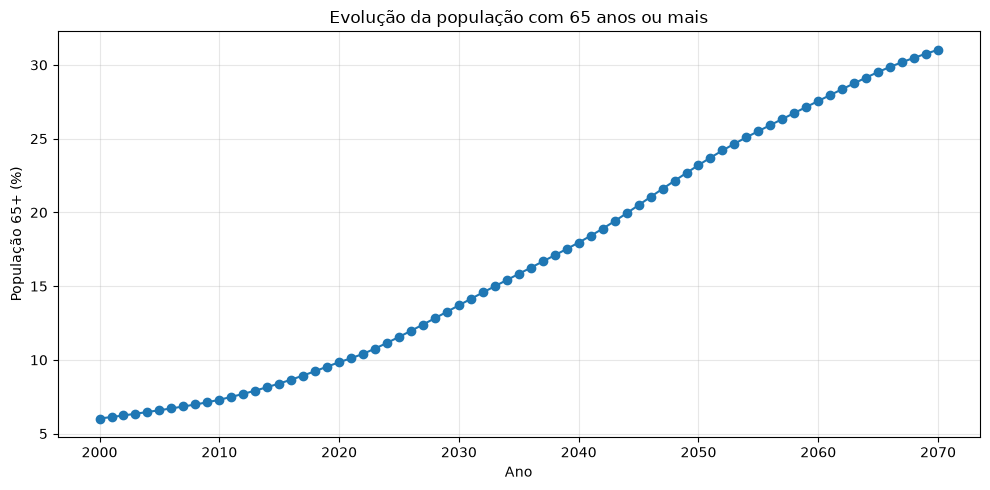

In [176]:
anos = sorted(PROJECAO_2024["ANO"].unique())

indicadores = []

for ano in anos:
    dados = PROJECAO_2024[PROJECAO_2024["ANO"] == ano]

    idosos = dados["65+_T"].sum()
    total = dados["POP_T"].sum()

    indicadores.append((idosos / total) * 100)

plt.figure(figsize=(10, 5))

plt.plot(anos, indicadores, marker="o")

plt.title("Evolução da população com 65 anos ou mais")
plt.xlabel("Ano")
plt.ylabel("População 65+ (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**idosos por 100 pessoas em idade ativa**

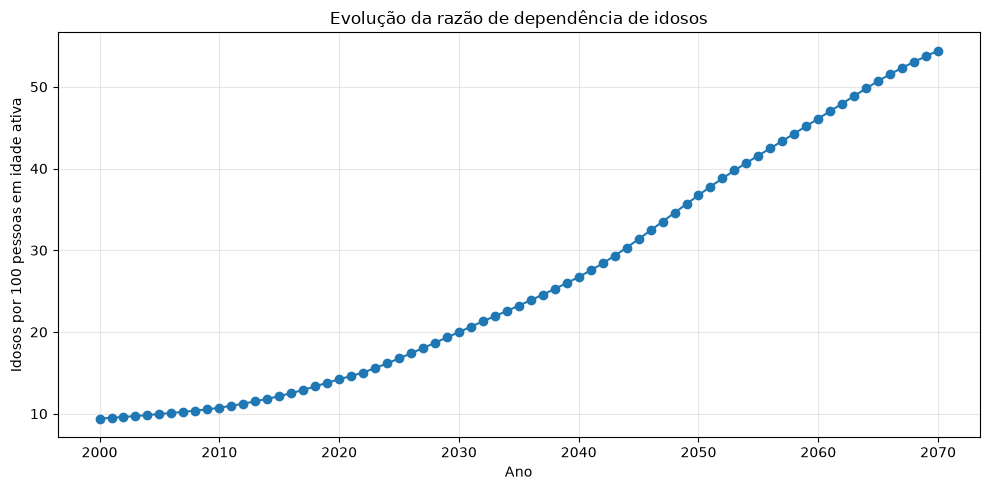

In [173]:
anos = sorted(PROJECAO_2024["ANO"].unique())

dependencia = []

for ano in anos:
    dados = PROJECAO_2024[PROJECAO_2024["ANO"] == ano]

    idosos = dados["65+_T"].sum()
    populacao_ativa = dados["15-64_T"].sum()

    dependencia.append((idosos / populacao_ativa) * 100)

plt.figure(figsize=(10, 5))

plt.plot(anos, dependencia, marker="o")

plt.title("Evolução da razão de dependência de idosos")
plt.xlabel("Ano")
plt.ylabel("Idosos por 100 pessoas em idade ativa")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

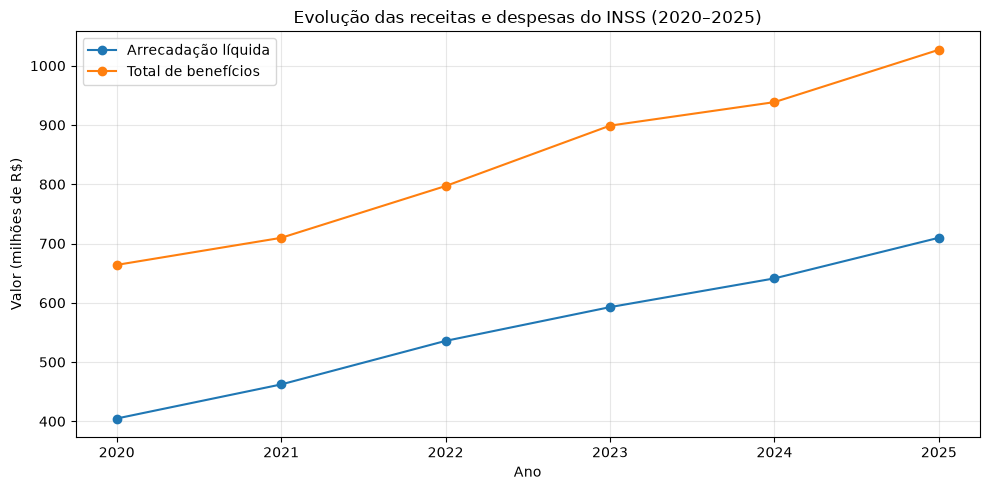

In [169]:
anos = list(range(2020, 2026))

receitas = []
despesas = []

for ano in anos:
    df = globals()[f"FINANCAS_INSS_{ano}"]
    total = df.loc[df["Mes"] == "Total"].iloc[0]

    receitas.append(total["Arrecadacao_Liquida"] / 1_000_000)
    despesas.append(total["Total_Beneficios"] / 1_000_000)

plt.figure(figsize=(10, 5))

plt.plot(anos, receitas, marker="o", label="Arrecadação líquida")
plt.plot(anos, despesas, marker="o", label="Total de benefícios")

plt.title("Evolução das receitas e despesas do INSS (2020–2025)")
plt.xlabel("Ano")
plt.ylabel("Valor (milhões de R$)")
plt.xticks(anos)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

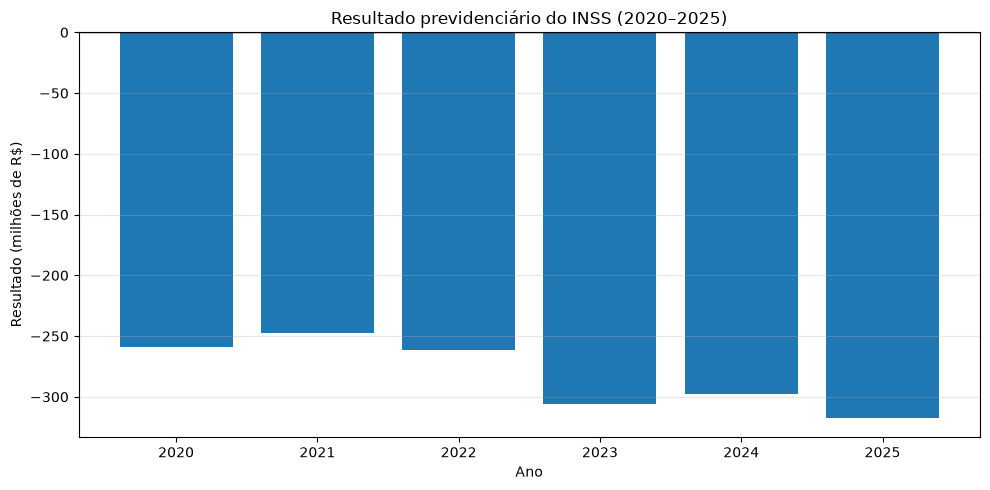

In [170]:
resultados = []

for ano in anos:
    df = globals()[f"FINANCAS_INSS_{ano}"]

    resultado = df.loc[
        df["Mes"] == "Total", "Resultado_Primario"
    ].iloc[0]

    resultados.append(resultado / 1_000_000)

plt.figure(figsize=(10, 5))

plt.bar(anos, resultados)

plt.axhline(y=0, linewidth=1, color="black")
plt.title("Resultado previdenciário do INSS (2020–2025)")
plt.xlabel("Ano")
plt.ylabel("Resultado (milhões de R$)")
plt.xticks(anos)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()